# DeepSense-X — Phase 2: LSTM Autoencoder

**Goal:** Learn normal MetroPT-3 sensor behaviour from February 2020 training windows, then detect unusual windows using reconstruction error.

**Input:** `DeepSense_X_MetroPT3/processed/metropt3_phase1_windows.npz` from Phase 1.

**Outputs:** Trained LSTM Autoencoder, validation-based anomaly threshold, test predictions, metrics, plots, and saved model/results.

> This is unsupervised anomaly detection. It does not predict Remaining Useful Life (RUL). Detecting a window during a documented failure is not the same as predicting a failure in advance.


## 0. Install/import libraries and set random seeds

In [1]:
import os, json, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, classification_report

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.21.0
GPU: []


## 1. Mount Drive and load Phase 1 arrays

If your Phase 1 folder or filename differs, edit `DATA_PATH`.

In [3]:

from google.colab import drive
from pathlib import Path
import numpy as np
import pandas as pd

# Mount Google Drive
drive.mount('/content/drive')

# Locate Phase 1 saved data
BASE_DIR = Path("/content/drive/MyDrive/DeepSense_X_MetroPT3")
DATA_PATH = BASE_DIR / "processed" / "metropt3_phase1_windows.npz"

# Load saved arrays
phase1 = np.load(DATA_PATH, allow_pickle=True)

print("Available keys:", phase1.files)

# Use the actual saved variable names
X_train = phase1["X_train"].astype("float32")
X_val = phase1["X_val"].astype("float32")
X_test = phase1["X_test"].astype("float32")

y_test = phase1["y_test_event"].astype("int32").reshape(-1)

# Verify dimensions
print("\nPHASE 1 DATA LOADED SUCCESSFULLY")
print("--------------------------------")
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)
print("Test labels:", y_test.shape)

assert X_train.ndim == 3
assert X_val.ndim == 3
assert X_test.ndim == 3
assert X_train.shape[1:] == X_val.shape[1:] == X_test.shape[1:]
assert len(X_test) == len(y_test)

print("\nSUCCESS: All data checks passed!")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Available keys: ['X_train', 'X_val', 'X_test', 'train_scores', 'val_scores', 'test_scores', 'test_window_times', 'y_test_event', 'y_test_anomaly_pred_baseline']

PHASE 1 DATA LOADED SUCCESSFULLY
--------------------------------
Training: (214791, 60, 13)
Validation: (230389, 60, 13)
Testing: (524836, 60, 13)
Test labels: (524836,)

SUCCESS: All data checks passed!


## 2. Validate data

In [4]:
assert X_train.ndim == X_val.ndim == X_test.ndim == 3
assert X_train.shape[1:] == X_val.shape[1:] == X_test.shape[1:]
assert len(X_test) == len(y_test), "Test windows and labels are not aligned."
for name, arr in [("train", X_train), ("validation", X_val), ("test", X_test)]:
    print(name, arr.shape, "finite:", np.isfinite(arr).all(),
          "range:", float(arr.min()), "to", float(arr.max()))
    if not np.isfinite(arr).all():
        raise ValueError(f"{name} has NaN or infinite values.")
N_TIMESTEPS, N_FEATURES = X_train.shape[1], X_train.shape[2]
print(f"Model input: {N_TIMESTEPS} time steps × {N_FEATURES} features")


train (214791, 60, 13) finite: True range: -36.291847229003906 to 463.51806640625
validation (230389, 60, 13) finite: True range: -36.291847229003906 to 463.51806640625
test (524836, 60, 13) finite: True range: -36.291847229003906 to 463.51806640625
Model input: 60 time steps × 13 features


## 3. Choose training size

The full training set can be large. Start with up to 100,000 windows for a first run. Set `MAX_TRAIN_WINDOWS = None` to use all February training windows.

In [8]:
SEED = 42
rng = np.random.default_rng(SEED)

# Training: 5,000 windows
train_idx = np.sort(
    rng.choice(len(X_train), 5000, replace=False)
)
X_train_fit = X_train[train_idx]

# Validation: 2,000 windows
val_idx = np.sort(
    rng.choice(len(X_val), 2000, replace=False)
)
X_val_fit = X_val[val_idx]

# Testing: 10,000 windows
test_idx = np.sort(
    rng.choice(len(X_test), 10000, replace=False)
)
X_test_eval = X_test[test_idx]
y_test_eval = y_test[test_idx]

print("Training:", X_train_fit.shape)
print("Validation:", X_val_fit.shape)
print("Testing:", X_test_eval.shape)

Training: (5000, 60, 13)
Validation: (2000, 60, 13)
Testing: (10000, 60, 13)


## 4. Build the LSTM Autoencoder

The encoder compresses a sensor sequence into a smaller representation. The decoder reconstructs the original sequence. Large reconstruction error can indicate unusual behaviour.

In [9]:

LATENT_DIM = 16

inputs = keras.Input(
    shape=(N_TIMESTEPS, N_FEATURES),
    name="sensor_window"
)

# Encoder
x = layers.LSTM(32, return_sequences=True)(inputs)
x = layers.LSTM(LATENT_DIM, return_sequences=False)(x)

# Latent representation
x = layers.RepeatVector(N_TIMESTEPS)(x)

# Decoder
x = layers.LSTM(LATENT_DIM, return_sequences=True)(x)
x = layers.LSTM(32, return_sequences=True)(x)

outputs = layers.TimeDistributed(
    layers.Dense(N_FEATURES),
    name="reconstruction"
)(x)

lstm_autoencoder = keras.Model(
    inputs, outputs,
    name="DeepSenseX_LSTM_Autoencoder"
)

lstm_autoencoder.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mae"
)

lstm_autoencoder.summary()


Model: "DeepSenseX_LSTM_Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sensor_window (InputLayer)      │ (None, 60, 13)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 60, 32)         │         5,888 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 16)             │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector_1 (RepeatVector)  │ (None, 60, 16)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 60, 16)         │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 60, 32)         │         6,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reconstruction                  │ (None, 60, 13)         │           429 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,837 (69.68 KB)

 Trainable params: 17,837 (69.68 KB)

 Non-trainable params: 0 (0.00 B)

## 5. Train

Only February training windows are used for fitting. March is used for validation. Test data is not used for training or threshold selection.

In [10]:

# Create artifacts directory
ARTIFACT_DIR = BASE_DIR / "artifacts"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

# Callbacks
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ModelCheckpoint(
        str(ARTIFACT_DIR / "phase2_lstm_autoencoder.keras"),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

# Train lightweight LSTM Autoencoder
history = lstm_autoencoder.fit(
    X_train_fit,
    X_train_fit,
    validation_data=(X_val_fit, X_val_fit),
    epochs=3,
    batch_size=128,
    shuffle=True,
    callbacks=callbacks,
    verbose=1
)

print("LSTM Autoencoder training completed!")


Epoch 1/3
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step - loss: 0.4240
Epoch 1: val_loss improved from None to 0.81890, saving model to /content/drive/MyDrive/DeepSense_X_MetroPT3/artifacts/phase2_lstm_autoencoder.keras

Epoch 1: finished saving model to /content/drive/MyDrive/DeepSense_X_MetroPT3/artifacts/phase2_lstm_autoencoder.keras
40/40 ━━━━━━━━━━━━━━━━━━━━ 16s 234ms/step - loss: 0.3850 - val_loss: 0.8189
Epoch 2/3
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step - loss: 0.3136
Epoch 2: val_loss improved from 0.81890 to 0.78841, saving model to /content/drive/MyDrive/DeepSense_X_MetroPT3/artifacts/phase2_lstm_autoencoder.keras

Epoch 2: finished saving model to /content/drive/MyDrive/DeepSense_X_MetroPT3/artifacts/phase2_lstm_autoencoder.keras
40/40 ━━━━━━━━━━━━━━━━━━━━ 6s 140ms/step - loss: 0.3056 - val_loss: 0.7884
Epoch 3/3
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 173ms/step - loss: 0.2797
Epoch 3: val_loss improved from 0.78841 to 0.75849, saving model to /content/drive/MyDrive/DeepSense_X_MetroPT3/

## 6. Plot training history

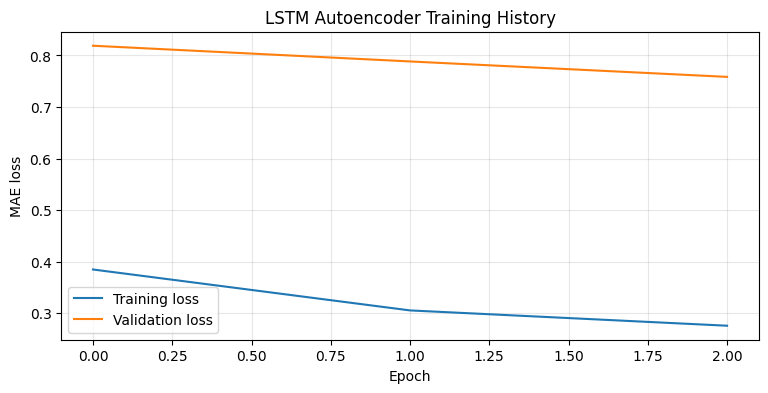

In [11]:
plt.figure(figsize=(9,4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("MAE loss")
plt.title("LSTM Autoencoder Training History")
plt.legend(); plt.grid(alpha=0.3); plt.show()


## 7. Calculate reconstruction errors

In [12]:

def reconstruction_errors(model, X, batch_size=128):
    reconstructed = model.predict(
        X,
        batch_size=batch_size,
        verbose=1
    )

    errors = np.mean(
        np.abs(X - reconstructed),
        axis=(1, 2)
    )

    return errors.astype("float32")


# Use lightweight subsets selected in Section 3
val_errors = reconstruction_errors(
    lstm_autoencoder, X_val_fit
)

test_errors = reconstruction_errors(
    lstm_autoencoder, X_test_eval
)

print("Validation errors:", val_errors.shape)
print("Test errors:", test_errors.shape)

print(
    "Validation percentiles:",
    np.percentile(val_errors, [50, 90, 95, 99, 99.5, 99.9])
)


16/16 ━━━━━━━━━━━━━━━━━━━━ 9s 196ms/step
79/79 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step
Validation errors: (2000,)
Test errors: (10000,)
Validation percentiles: [ 0.41763461  1.18772174  2.96772962  3.24130372  6.27416243 32.72082191]


## 8. Set anomaly threshold from validation only

The 99th percentile is an initial operating point: roughly the top 1% of March validation reconstruction errors exceed it. This is a tunable design choice, not a universal threshold. Do not tune it against test labels.

In [13]:
THRESHOLD_PERCENTILE = 99.0

anomaly_threshold = float(
    np.percentile(val_errors, THRESHOLD_PERCENTILE)
)

print("Threshold:", anomaly_threshold)

print("Validation flagged:",
      int((val_errors > anomaly_threshold).sum()),
      f"({100*np.mean(val_errors > anomaly_threshold):.2f}%)")

Threshold: 3.2413036823272705
Validation flagged: 20 (1.00%)


## 9. Predict anomalies on the test set

In [14]:

# Predict anomalies using the validation threshold
test_predictions = (
    test_errors > anomaly_threshold
).astype("int32")

print("Predicted anomalous windows:", int(test_predictions.sum()))

print(
    "Predicted anomaly percentage:",
    f"{100 * test_predictions.mean():.2f}%"
)

print(
    "Event-labelled test windows:",
    int(y_test_eval.sum())
)


Predicted anomalous windows: 947
Predicted anomaly percentage: 9.47%
Event-labelled test windows: 516


## 10. Evaluate on documented event-period labels

Phase 1 labels indicate windows whose endpoint lies inside one of the three documented failure intervals present in this CSV. These metrics measure detection during the event periods, not advance warning. Overlapping windows are correlated, so treat the results as preliminary.

In [15]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Evaluate sampled test predictions
precision = precision_score(
    y_test_eval, test_predictions, zero_division=0
)

recall = recall_score(
    y_test_eval, test_predictions, zero_division=0
)

f1 = f1_score(
    y_test_eval, test_predictions, zero_division=0
)

cm = confusion_matrix(
    y_test_eval, test_predictions, labels=[0, 1]
)

print(f"Precision: {precision:.4f} ({precision*100:.2f}%)")
print(f"Recall:    {recall:.4f} ({recall*100:.2f}%)")
print(f"F1-score:  {f1:.4f} ({f1*100:.2f}%)")

print("\nConfusion Matrix [[TN, FP], [FN, TP]]:")
print(cm)

print("\nClassification Report:")
print(classification_report(
    y_test_eval,
    test_predictions,
    zero_division=0
))


Precision: 0.5417 (54.17%)
Recall:    0.9942 (99.42%)
F1-score:  0.7013 (70.13%)

Confusion Matrix [[TN, FP], [FN, TP]]:
[[9050  434]
 [   3  513]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.95      0.98      9484
           1       0.54      0.99      0.70       516

    accuracy                           0.96     10000
   macro avg       0.77      0.97      0.84     10000
weighted avg       0.98      0.96      0.96     10000



## 11. Event-wise detection summary

This uses saved test window timestamps if Phase 1 included them.

In [16]:

event_intervals = {
    "Event 1 (18 Apr 2020)": ("2020-04-18 00:00:00", "2020-04-19 00:00:00"),
    "Event 2 (29-30 May 2020)": ("2020-05-29 23:30:00", "2020-05-30 06:00:00"),
    "Event 3 (5-7 Jun 2020)": ("2020-06-05 10:00:00", "2020-06-07 14:30:00"),
}

# Align full test timestamps with the sampled test windows
test_times_eval = pd.to_datetime(
    phase1["test_window_times"]
)[test_idx]

rows = []

for name, (start, end) in event_intervals.items():
    mask = (
        (test_times_eval >= pd.Timestamp(start)) &
        (test_times_eval <= pd.Timestamp(end))
    )

    total = int(mask.sum())
    flagged = int(test_predictions[mask].sum())

    rows.append({
        "Event": name,
        "Sampled event windows": total,
        "Detected windows": flagged,
        "Detection rate (%)": round(100 * flagged / total, 2)
        if total else np.nan
    })

display(pd.DataFrame(rows))


,Event,Sampled event windows,Detected windows,Detection rate (%)
0,Event 1 (18 Apr 2020),147,145,98.64
1,Event 2 (29-30 May 2020),47,46,97.87
2,Event 3 (5-7 Jun 2020),322,322,100.00


## 12. Visualise reconstruction errors

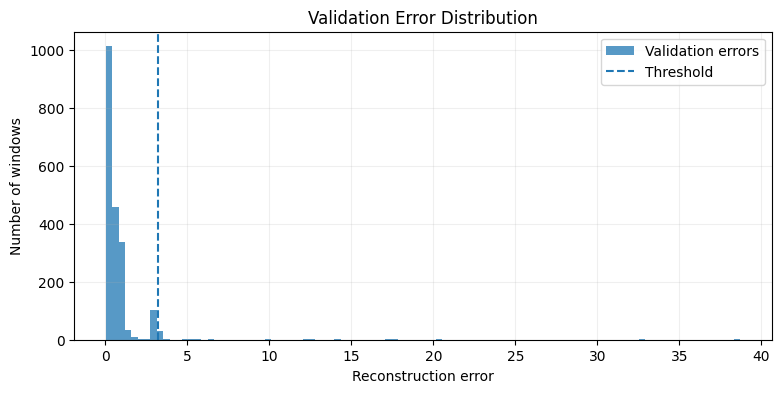

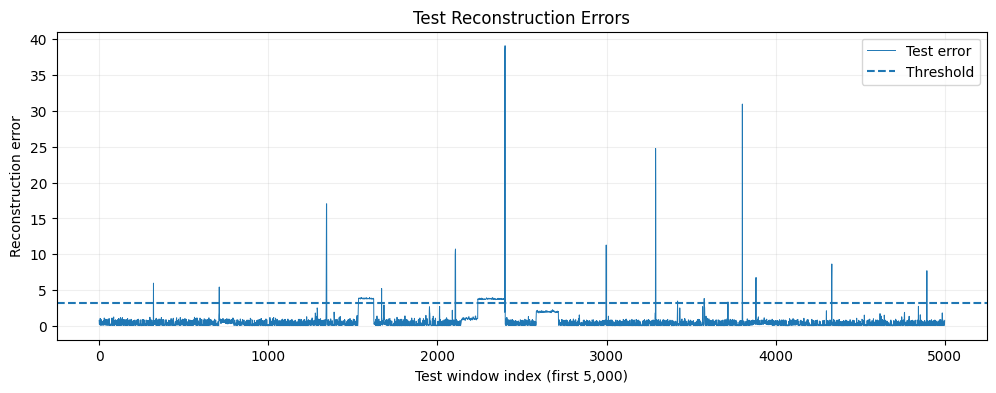

In [17]:

plt.figure(figsize=(9,4))
plt.hist(val_errors, bins=100, alpha=0.75, label="Validation errors")
plt.axvline(anomaly_threshold, linestyle="--", label="Threshold")
plt.xlabel("Reconstruction error")
plt.ylabel("Number of windows")
plt.title("Validation Error Distribution")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

plt.figure(figsize=(12,4))
plt.plot(test_errors[:5000], linewidth=0.7, label="Test error")
plt.axhline(anomaly_threshold, linestyle="--", label="Threshold")
plt.xlabel("Test window index (first 5,000)")
plt.ylabel("Reconstruction error")
plt.title("Test Reconstruction Errors")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


## 13. Save Phase 2 model and results

In [18]:

import json
import numpy as np

# 1. Save trained LSTM Autoencoder
final_model_path = ARTIFACT_DIR / "phase2_lstm_autoencoder_final.keras"
lstm_autoencoder.save(final_model_path)

# 2. Save evaluation results
results_path = BASE_DIR / "processed" / "metropt3_phase2_lstm_results.npz"

np.savez_compressed(
    results_path,
    val_errors=val_errors,
    test_errors=test_errors,
    test_predictions=test_predictions,
    y_test_event=y_test_eval,  # Corrected: sampled labels
    test_idx=test_idx,
    threshold=np.array(anomaly_threshold, dtype="float32")
)

# 3. Save metadata
metadata = {
    "phase": 2,
    "model": "LSTM Autoencoder",
    "input_shape": [int(N_TIMESTEPS), int(N_FEATURES)],

    "training_windows_available": int(len(X_train)),
    "training_windows_used": int(len(X_train_fit)),

    "validation_windows_available": int(len(X_val)),
    "validation_windows_used": int(len(X_val_fit)),

    "test_windows_available": int(len(X_test)),
    "test_windows_used": int(len(X_test_eval)),

    "threshold_percentile": float(THRESHOLD_PERCENTILE),
    "anomaly_threshold": float(anomaly_threshold),

    "precision": float(precision),
    "recall": float(recall),
    "f1_score": float(f1),
    "confusion_matrix": cm.tolist(),

    "evaluation_note": "Preliminary sampled event-period detection, not pre-failure forecasting."
}

with open(ARTIFACT_DIR / "phase2_lstm_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print("PHASE 2 SAVED SUCCESSFULLY!")
print("Model:", final_model_path)
print("Results:", results_path)
print("Metadata:", ARTIFACT_DIR / "phase2_lstm_metadata.json")


PHASE 2 SAVED SUCCESSFULLY!
Model: /content/drive/MyDrive/DeepSense_X_MetroPT3/artifacts/phase2_lstm_autoencoder_final.keras
Results: /content/drive/MyDrive/DeepSense_X_MetroPT3/processed/metropt3_phase2_lstm_results.npz
Metadata: /content/drive/MyDrive/DeepSense_X_MetroPT3/artifacts/phase2_lstm_metadata.json


## 14. Phase 2 completion checklist

After successful execution, you should have:
- A trained LSTM Autoencoder (`phase2_lstm_autoencoder_final.keras`)
- A threshold calculated from March validation reconstruction errors
- Test reconstruction errors and anomaly predictions
- Precision, recall, F1-score, and confusion matrix
- Training and error-distribution plots
- Saved Phase 2 model, results, and metadata

### Next phase
Phase 3 can implement a Transformer-based anomaly detector. After that, we can compare the baseline, LSTM Autoencoder, Transformer, and hybrid model using consistent splits and evaluation.

**Important research check:** Ensure Phase 1 windows are gap-aware and that each test window timestamp and event label refer to the same window endpoint. If they are misaligned, the evaluation metrics will not be valid.
